# Submission Summary

| Required field | Group 30 submission |
|---|---|
| **Group number** | 30 |
| **Submitting student** | Peace Ola-Stephen |
| **Dataset** | Stroke Prediction |
| **Depth track** | Classification Depth |
| **Team members** | Peace Ola-Stephen; Usman Abdulbasit Abdullateef; Saint Ogheneroboh; Uyime George Anthony; Mercy Princess Momoh; Chiamaka Doris Umeh; Okon Esther Wilson; Babatunde Michael Olawole; Nnali Izuchukwu Henry; James Titilope Love; Nurudeen Faruq Ayomide; Ewomazino Elizabeth Egbeme |
| **Final model** | Logistic Regression with validation-selected business-cost threshold = 0.12 (false-negative:false-positive cost = 5:1) |
| **Stratified dummy F1 / ROC AUC** | 0.0435 / 0.4994 |
| **Final model F1 / ROC AUC** | 0.2990 / 0.8377 |
| **Leakage controls** | `id` removed; scaling fitted on training data; threshold selected on a validation subset; test set used once for final evaluation. |
| **Full run time** | Printed automatically in the final reproducibility cell after **Restart and Run All**. |

In [1]:
%pip install -q kagglehub imbalanced-learn


# Part 1. Data Foundation

This section downloads the assigned Stroke Prediction dataset from Kaggle, stores the raw data in SQLite, answers three questions with SQL, performs exploratory data analysis, and documents the cleaning decisions.


In [2]:
import kagglehub
import pandas as pd
import numpy as np
import sqlite3
import matplotlib.pyplot as plt
import os
import time
import warnings

warnings.filterwarnings("ignore")
notebook_start_time = time.perf_counter()
print("Core libraries imported successfully.")


Core libraries imported successfully.


## 1.1 Load the Dataset from Kaggle

`kagglehub.dataset_download()` downloads the assigned dataset into the notebook environment. The returned folder path is inspected before the CSV is loaded into Pandas, making the workflow reproducible in a fresh Colab session.


In [3]:
path = kagglehub.dataset_download("fedesoriano/stroke-prediction-dataset")   # tells kagglehub to download kaggle dataset into my colab environment
print("Path to dataset files:", path)

Using Colab cache for faster access to the 'stroke-prediction-dataset' dataset.
Path to dataset files: /kaggle/input/stroke-prediction-dataset


### Inspect the downloaded folder
Before assuming the CSV filename, this cell lists the files inside the downloaded dataset folder with `os.listdir(path)`.

This is a useful validation step because it confirms the exact filename supplied by Kaggle. In the current output, the dataset file is `healthcare-dataset-stroke-data.csv`.

In [4]:
os.listdir(path)    # to know the actual file name of the dataset downloaded by kagglehub

['healthcare-dataset-stroke-data.csv']

### Load the CSV into a pandas DataFrame
This cell joins the dataset folder path and CSV filename to create `file_path`, then reads the CSV into a DataFrame named `df`.

`df.head()` displays the first five rows so we can confirm that the file loaded correctly and see the structure of the data. The dataset contains patient-level variables such as age, hypertension, heart disease, glucose level, BMI, smoking status, and the stroke outcome.

In [5]:
file_path = os.path.join(path, 'healthcare-dataset-stroke-data.csv')
df = pd.read_csv(file_path)   # kaggle data becomes a pandas dataframe
print(file_path)
df.head()

/kaggle/input/stroke-prediction-dataset/healthcare-dataset-stroke-data.csv


,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


## 1.2 Load the Data into SQLite

The raw DataFrame is written to a SQLite table called `stroke_data`. `if_exists='replace'` refreshes the table during a full rerun, and `index=False` prevents the Pandas row index from becoming an unnecessary database column.


In [6]:
conn = sqlite3.connect("stroke_prediction.db")   # this creates a SQLite database file in the current working directory
df.to_sql("stroke_data", conn, if_exists = "replace", index = False)   # this writes the pandas dataframe to a table named "stroke_data" in the SQLite database, if the table already exists, it will be replaced. Dont save the pandasindex as a column in the database table.
print("Dataset sucessfully loaded into SQLite")

Dataset sucessfully loaded into SQLite


### Verify the SQLite table
This cell runs a simple SQL query that selects the first five rows from `stroke_data`.

The purpose is to confirm that the transfer from pandas to SQLite was successful. Because the returned rows match the source data, the SQL table is ready for analysis.

In [7]:
# to verify that the data has been loaded correctly, we run a simple SQL query to retrieve the first 5 rows of the stroke_data table.

query = """ 
SELECT *
FROM stroke_data
LIMIT 5;
"""

pd.read_sql_query(query, conn)

,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


## 1.3 SQL Analysis

The following three queries investigate age, hypertension, and combined cardiometabolic conditions. Because `stroke` is coded as 0 or 1, `AVG(stroke) * 100` returns the observed stroke percentage within each group.


### Query 1 — Stroke rate by age group
This query groups patients into five age ranges and calculates two values for each group:

1. the number of patients in the group; and
2. the percentage who had a stroke.

The corrected group labels are **Under 18**, **18–29**, **30–44**, **45–59**, and **60+**. The groups are ordered from the highest observed stroke rate to the lowest.

In [8]:
query1 = """
SELECT
    CASE
            WHEN age < 18 THEN 'Under 18'
            WHEN age < 30 THEN '18-29'
            WHEN age < 45 THEN '30-44'
            WHEN age < 60 THEN '45-59'
            ELSE '60_plus'
    END AS age_group,

    COUNT(*) AS total_patients,
    ROUND(AVG(stroke) * 100, 2) AS stroke_rate_percentage

FROM stroke_data
GROUP BY age_group                     
ORDER BY stroke_rate_percentage DESC;
"""
# grouping the data by age group to calculate the stroke rate for each age group

pd.read_sql_query(query1, conn)

,age_group,total_patients,stroke_rate_percentage
0,60_plus,1376,13.15
1,45-59,1201,4.83
2,30-44,1018,0.79
3,Under 18,856,0.23
4,18-29,659,0.00


**Interpretation:** In this dataset, the **60+** group has the highest observed stroke rate at **13.15%** (1,376 patients). The **45–59** group follows at **4.83%**, while the observed rates are much lower among younger groups: **0.79%** for ages 30–44, **0.23%** for under 18, and **0.00%** for ages 18–29.

This is a descriptive pattern in this dataset; it shows association, not proof that age alone causes stroke.

### Query 2 — Stroke rate by hypertension status
This query compares patients with and without hypertension. For each group it reports the total number of patients, the number of stroke cases, and the observed stroke rate.

This helps determine whether stroke outcomes differ between the two hypertension groups in the dataset.

In [9]:
query2 = """
SELECT
    hypertension,
    COUNT(*) AS total_patients,
    SUM(stroke) AS stroke_cases,
    ROUND(AVG(stroke) * 100, 2) AS stroke_rate
FROM stroke_data
GROUP BY hypertension;
"""

pd.read_sql_query(query2, conn)

,hypertension,total_patients,stroke_cases,stroke_rate
0,0,4612,183,3.97
1,1,498,66,13.25


**Interpretation:** Among patients without hypertension, **183 of 4,612** had a stroke, giving an observed stroke rate of **3.97%**. Among patients with hypertension, **66 of 498** had a stroke, corresponding to **13.25%**.

The observed stroke rate is therefore substantially higher in the hypertension group within this dataset. This result is descriptive and does not by itself establish causation.

### Query 3 — Combined hypertension and heart-disease risk among patients over 50
This query focuses only on patients older than 50 and groups them using both `hypertension` and `heart_disease`.

The four combinations allow us to compare patients with neither condition, one of the conditions, or both conditions. For each combination, the query reports the number of patients, stroke cases, and stroke rate.

In [10]:
query3 = """
SELECT hypertension, heart_disease, COUNT(*) AS number_of_patients, SUM(stroke) AS stroke_cases, ROUND(AVG(stroke) * 100, 2) AS stroke_rate_percentage
FROM stroke_data
WHERE age > 50
GROUP BY hypertension, heart_disease;
"""
pd.read_sql_query(query3, conn)

,hypertension,heart_disease,number_of_patients,stroke_cases,stroke_rate_percentage
0,0,0,1529,129,8.44
1,0,1,195,34,17.44
2,1,0,341,50,14.66
3,1,1,62,13,20.97


**Interpretation:** For patients over 50, the highest observed stroke rate occurs among those with **both hypertension and heart disease: 20.97%** (13 stroke cases among 62 patients). Patients with heart disease but no hypertension have a rate of **17.44%**, while those with hypertension but no heart disease have a rate of **14.66%**. Patients with neither condition have the lowest rate in this comparison at **8.44%**.

The smallest group contains only 62 patients, so its percentage should be interpreted with more caution than results based on larger groups.

## 1.4 Exploratory Data Analysis (EDA)

EDA checks the dataset's shape, data types, missing values, target balance, important distributions, and numerical summary before cleaning or modeling begins.


### Check the size of the dataset
`df.shape` returns the number of rows and columns. The two print statements present those values in a reader-friendly format.

The current dataset contains **5,110 patient records** and **12 columns** before cleaning.

In [11]:
df.shape
print(f"Number of rows: {df.shape[0]}")
print(f"Number of columns: {df.shape[1]}")

Number of rows: 5110
Number of columns: 12


### Inspect column data types
`df.dtypes` shows how pandas currently stores each variable.

Numeric columns include `age`, `hypertension`, `heart_disease`, `avg_glucose_level`, `bmi`, and `stroke`, while text-based categorical columns include variables such as `gender`, `ever_married`, `work_type`, `Residence_type`, and `smoking_status`.

This distinction matters because categorical variables usually need to be encoded before many machine-learning models can use them.

In [12]:
df.dtypes       

,0
id,int64
gender,object
age,float64
hypertension,int64
heart_disease,int64
ever_married,object
work_type,object
Residence_type,object
avg_glucose_level,float64
bmi,float64


### Review the DataFrame structure and non-null counts
`df.info()` gives a compact summary of the dataset: row count, column names, data types, number of non-null values, and approximate memory usage.

A key finding here is that `bmi` has **4,909 non-null values out of 5,110**, indicating missing BMI records. The other columns shown have complete values.

In [13]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 5110 non-null   int64  
 1   gender             5110 non-null   object 
 2   age                5110 non-null   float64
 3   hypertension       5110 non-null   int64  
 4   heart_disease      5110 non-null   int64  
 5   ever_married       5110 non-null   object 
 6   work_type          5110 non-null   object 
 7   Residence_type     5110 non-null   object 
 8   avg_glucose_level  5110 non-null   float64
 9   bmi                4909 non-null   float64
 10  smoking_status     5110 non-null   object 
 11  stroke             5110 non-null   int64  
dtypes: float64(3), int64(4), object(5)
memory usage: 479.2+ KB


### Count missing values by column
This cell counts null values in every column and sorts the result from the most missing to the least.

The output confirms that **BMI is the only column with missing values**, with **201 missing entries**. Identifying missingness before cleaning prevents accidental data loss or inconsistent modeling inputs.

In [14]:
df.isna().sum().sort_values(ascending=False)

,0
bmi,201
id,0
age,0
gender,0
hypertension,0
heart_disease,0
work_type,0
ever_married,0
Residence_type,0
avg_glucose_level,0


### Examine the target variable: `stroke`
The `stroke` column is the target we ultimately want to understand or predict. `value_counts(normalize=True)` calculates the proportion of each class, and multiplying by 100 converts those proportions into percentages.

The result shows that approximately **95.13%** of records are `0` (no stroke) and **4.87%** are `1` (stroke). This is a **strong class imbalance**, which will be important when choosing model-evaluation metrics later.

In [15]:
df["stroke"].value_counts(normalize=True) * 100

,proportion
stroke,
0,95.127202
1,4.872798


### Visualise the target distribution
This bar chart shows the absolute number of patients in the two target classes: **No Stroke** and **Stroke**.

The chart makes the class imbalance easier to see than percentages alone. Because stroke cases are much less common, overall accuracy by itself could be misleading in a future prediction model; metrics such as recall, precision, F1-score, and ROC-AUC may also be useful.

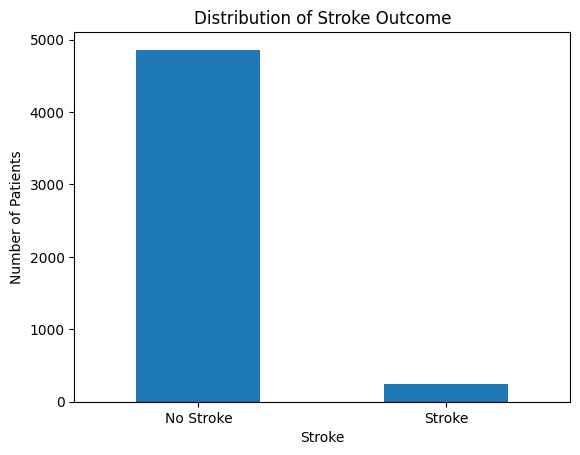

In [16]:
df["stroke"].value_counts().plot(kind='bar')

plt.title("Distribution of Stroke Outcome")
plt.xlabel("Stroke")
plt.ylabel("Number of Patients")
plt.xticks([0,1], ["No Stroke", "Stroke"], rotation = 0)
plt.show()

### Visualise the age distribution
This histogram divides the `age` variable into 20 intervals and shows how many patients fall into each interval.

The chart helps us see the age range, concentration of observations, and whether some age groups are more represented than others. Understanding this distribution is also useful because the earlier SQL analysis showed that stroke rates differ strongly across age groups.

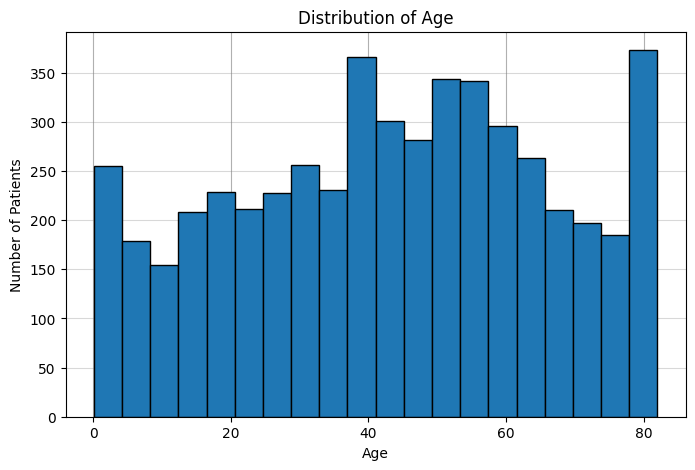

In [17]:
plt.figure(figsize=(8,5))

ax = df["age"].hist(bins=20, edgecolor="black")

# Customize the grid and axis
ax.grid(True, axis='y', color='gray', alpha=0.3)
ax.set_axisbelow(True)

# Add labels and title
ax.set_title("Distribution of Age")
ax.set_xlabel("Age")
ax.set_ylabel("Number of Patients")

plt.show()


### Visualise average glucose level
This histogram shows the distribution of `avg_glucose_level` across patients.

The purpose is to identify the typical range, spread, possible skewness, and unusually high values before feature engineering or modeling. The summary statistics later show a mean of about **106.15** and a median of about **91.89**, suggesting that higher values pull the mean upward.

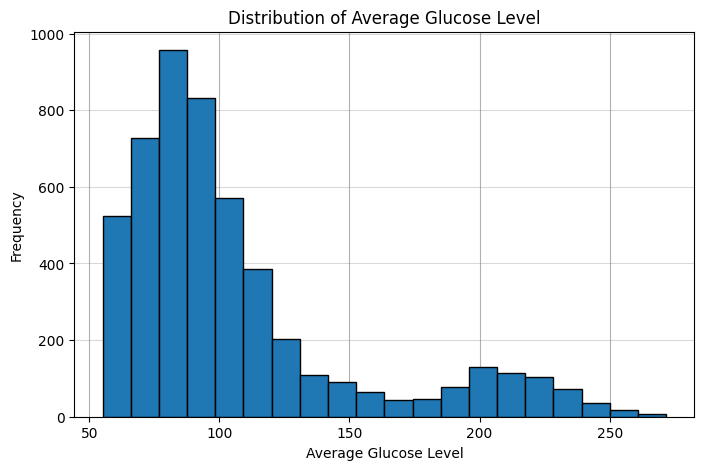

In [18]:
plt.figure(figsize=(8,5))

ax = df["avg_glucose_level"].hist(bins=20, edgecolor="black")

# Customize the grid and axis
ax.grid(True, axis='y', color='gray', alpha=0.3)
ax.set_axisbelow(True)

# Add labels and title
ax.set_title("Distribution of Average Glucose Level")
ax.set_xlabel("Average Glucose Level")
ax.set_ylabel("Frequency")

plt.show()


### Visualise BMI
This histogram displays the distribution of BMI values. `dropna()` is used only for the chart so that the 201 missing BMI records do not cause plotting problems.

At this stage the missing values have **not yet been filled**; the plot is simply based on the BMI values that are present. This keeps EDA separate from the later cleaning decision.

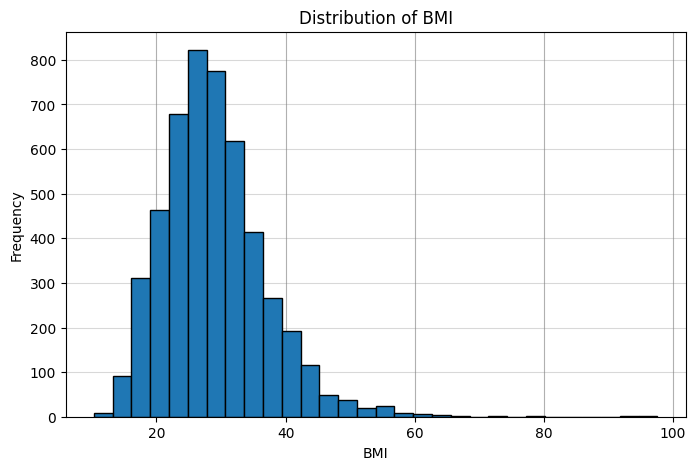

In [19]:
plt.figure(figsize=(8,5))

ax = df["bmi"].dropna().hist(bins=30, edgecolor="black")   # dropna() to remove any missing values in the bmi column before plotting the histogram

# Customize the grid and axis
ax.grid(True, axis='y', color='gray', alpha=0.3)
ax.set_axisbelow(True)

# Add labels and title
ax.set_title("Distribution of BMI")
ax.set_xlabel("BMI")
ax.set_ylabel("Frequency")

plt.show()


### Visualise gender distribution
This chart examines how patients are distributed across the values in the `gender` column.

Checking categorical balance is useful because a heavily over-represented group can influence how later results should be interpreted. For categorical variables, a value-count bar chart is generally easier to interpret than a numeric-style histogram, but this cell still provides a quick view of the recorded gender categories.

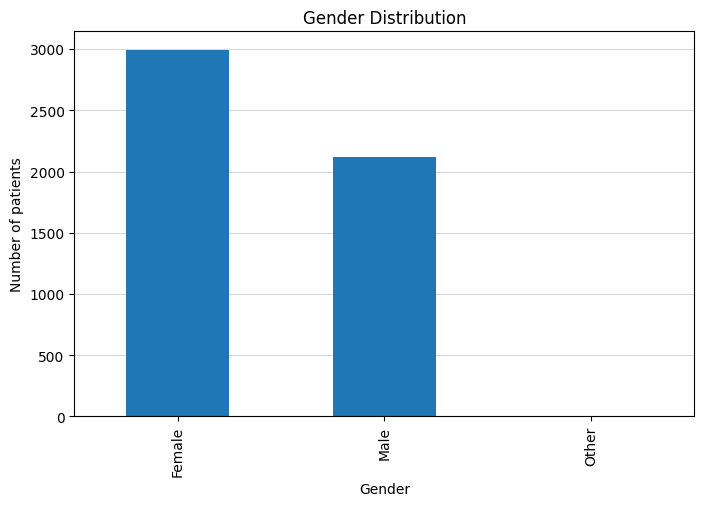

In [20]:
plt.figure(figsize=(8,5))

ax = df["gender"].value_counts().plot(kind='bar')   # value_counts() to count the number of occurrences of each gender category, and then plot a bar chart
# Customize the grid and axis
ax.grid(True, axis='y', color='gray', alpha=0.3)
ax.set_axisbelow(True)

# Add labels and title
ax.set_title("Gender Distribution")
ax.set_xlabel("Gender")
ax.set_ylabel("Number of patients")

plt.show()


### Visualise hypertension distribution
This bar chart counts how many patients have `hypertension = 0` and `hypertension = 1`.

It complements the earlier SQL result: the SQL query compared stroke rates between the two groups, while this chart shows the underlying number of observations in each group. This context is important because the hypertension group is much smaller than the non-hypertension group.

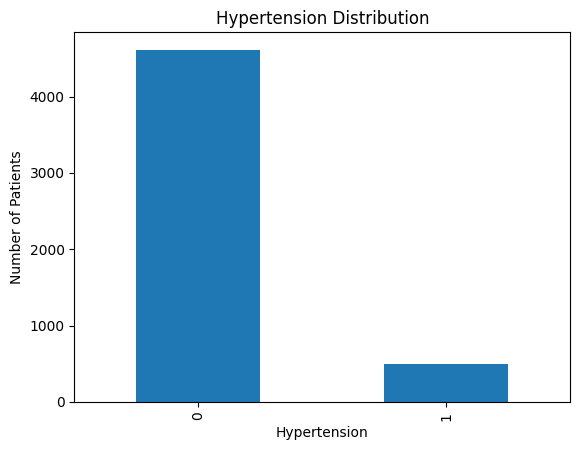

In [21]:
# cross check

df["hypertension"].value_counts().plot(kind="bar")

plt.title("Hypertension Distribution")
plt.xlabel("Hypertension")
plt.ylabel("Number of Patients")
plt.show()

### Visualise smoking-status distribution
This bar chart counts patients in each `smoking_status` category.

Rotating the x-axis labels makes longer category names easier to read. Reviewing category frequencies helps identify rare categories and gives an early indication of how this variable may need to be encoded later.

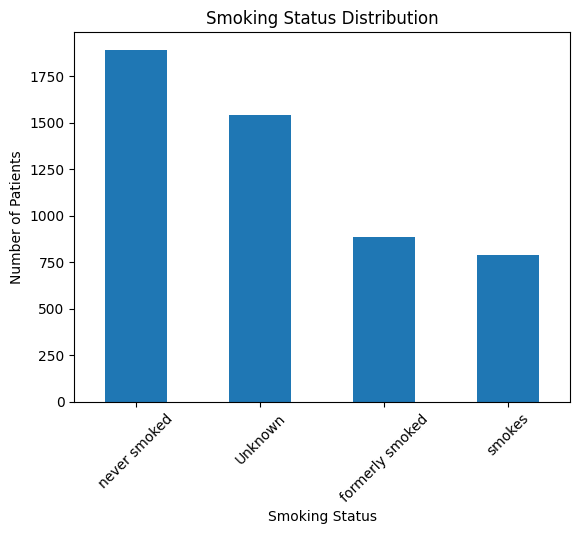

In [22]:
#cross check

df["smoking_status"].value_counts().plot(kind="bar")

plt.title("Smoking Status Distribution")
plt.xlabel("Smoking Status")
plt.ylabel("Number of Patients")
plt.xticks(rotation=45)
plt.show()

### Summarise the numerical variables before cleaning
`df.describe()` calculates count, mean, standard deviation, minimum, quartiles, and maximum for numeric columns.

A few useful reference points are visible in the output: median age is **45 years**, median average glucose level is about **91.89**, and median BMI is **28.1**. BMI has only **4,909** observations here because 201 values are missing. Its maximum value of **97.6** is also much higher than the upper quartile of **33.1**, so unusually large values may deserve later inspection rather than automatic removal.

In [23]:
df.describe()

,id,age,hypertension,heart_disease,avg_glucose_level,bmi,stroke
count,5110.000000,5110.000000,5110.000000,5110.000000,5110.000000,4909.000000,5110.000000
mean,36517.829354,43.226614,0.097456,0.054012,106.147677,28.893237,0.048728
std,21161.721625,22.612647,0.296607,0.226063,45.283560,7.854067,0.215320
min,67.000000,0.080000,0.000000,0.000000,55.120000,10.300000,0.000000
25%,17741.250000,25.000000,0.000000,0.000000,77.245000,23.500000,0.000000
50%,36932.000000,45.000000,0.000000,0.000000,91.885000,28.100000,0.000000
75%,54682.000000,61.000000,0.000000,0.000000,114.090000,33.100000,0.000000
max,72940.000000,82.000000,1.000000,1.000000,271.740000,97.600000,1.000000


## 1.5 Data Cleaning

Cleaning is performed on a copy named `df_clean`, preserving the raw DataFrame. Missing BMI values, duplicate rows, and the identifier column are addressed and verified below.


In [24]:
df_clean = df.copy()


### Check for duplicate rows
Before making any changes, we check whether the dataset contains exact
duplicate rows. Duplicates would double-count some patients and distort
both the SQL/EDA results already computed and any modeling done later.

This cell counts duplicates so the result can be reported and acted on,
rather than assumed.

In [25]:
n_duplicates = df_clean.duplicated().sum()
print(f"Duplicate rows found: {n_duplicates}")


Duplicate rows found: 0


### Fill missing BMI values using a per-age-decade median
201 `bmi` values are missing. Rather than filling all of them with a single
dataset-wide median (a blanket fillna, which ignores that BMI baselines
differ meaningfully by age — a child and a 70-year-old don't share a
realistic "typical" BMI), we group patients into age decades
(`age // 10 * 10`) and fill each missing value with the median BMI observed
within that same age decade. This preserves the age-BMI relationship instead
of pulling every missing value toward one global number.

`age_decade` is a helper column only, used purely to compute the grouped
median, and is dropped immediately afterward since it isn't a feature we
want to carry forward.

In [26]:
df_clean["age_decade"] = (df_clean["age"] // 10) * 10
df_clean["bmi"] = df_clean.groupby("age_decade")["bmi"].transform(
    lambda x: x.fillna(x.median())
)
df_clean = df_clean.drop(columns=["age_decade"])

print("Missing bmi values after grouped imputation:", df_clean["bmi"].isnull().sum())


Missing bmi values after grouped imputation: 0


### Remove the `id` Column

`id` identifies a record but does not describe the patient. Keeping it could encourage a model to learn meaningless patterns tied to arbitrary identification numbers, so it is removed before modeling.


In [27]:
df_clean = df_clean.drop(columns=["id"])  # explain why

### Validate the cleaning steps
This cell checks two things after cleaning:

- whether any BMI values are still missing; and
- which columns remain after removing `id`.

The output shows **0 missing BMI values** and confirms that `id` is no longer present.

In [28]:
# verify that the missing values have been imputed and the id column has been dropped
print("Missing values in bmi column:")
print(df_clean["bmi"].isnull().sum())
print("Columns in cleaned DataFrame:")
print(df_clean.columns.tolist())

Missing values in bmi column:
0
Columns in cleaned DataFrame:
['gender', 'age', 'hypertension', 'heart_disease', 'ever_married', 'work_type', 'Residence_type', 'avg_glucose_level', 'bmi', 'smoking_status', 'stroke']


### Confirm the cleaned dataset shape
`df_clean.shape` checks that the cleaning steps produced the expected dimensions.

The cleaned dataset contains **5,110 rows and 11 columns**. The number of rows is unchanged because BMI values were imputed rather than deleted; only one column (`id`) was removed.

In [29]:
df_clean.shape

(5110, 11)

# Part 2. Feature Engineering and Encoding

This section creates three meaningful features, converts categorical predictors into numerical form, and selects a scaling method for the distance- and scale-sensitive algorithms used later.


In [30]:
df_model = df_clean.copy()

`df_clean` is preserved as the cleaned reference dataset, while `df_model` is an independent modeling copy. Transformations can therefore be made without altering the cleaned data used for interpretation.


## 2.1 Feature Engineering

### Feature 1: Age Group

Age is retained as a continuous feature and also grouped into broad life stages. The grouped feature can represent non-linear age patterns and makes the later cluster profiles easier to interpret.


In [31]:
df_model["age_group"] = pd.cut(
    df_model["age"],
    bins=[0, 18, 30, 45, 60, float("inf")],
    labels=["Under 18", "18-29", "30-44", "45-59", "60+"],
    right=False
)

This cell converts the continuous `age` column into five categories using `pd.cut()`:

- Under 18
- 18–29
- 30–44
- 45–59
- 60+

`right=False` means the left boundary is included and the right boundary is excluded. For example, age 30 belongs to the 30–44 group, while age 45 starts the 45–59 group.

The earlier SQL analysis showed that observed stroke rates do not increase evenly across age. Age groups can make those non-linear differences easier to capture and explain.

**Business reasoning:** 
"Stroke risk research shows risk rises sharply and non-linearly after middle age. a bucket lets the model treat '60_plus' as a distinct group rather than assuming risk increases smoothly by exactly the same amount every year."

In [32]:
df_model[["age", "age_group"]].head(10)

,age,age_group
0,67.0,60+
1,61.0,60+
2,80.0,60+
3,49.0,45-59
4,79.0,60+
5,81.0,60+
6,74.0,60+
7,69.0,60+
8,59.0,45-59
9,78.0,60+


In [33]:
df_model["age_group"].value_counts().sort_index()

,count
age_group,
Under 18,856
18-29,659
30-44,1018
45-59,1201
60+,1376


### Feature 2: Comorbidity Count

`comorbidity_count` adds the hypertension and heart-disease indicators. It ranges from 0 to 2 and summarizes how many of these recorded conditions are present without replacing the original variables.

Because both original columns are binary (0 or 1), the new feature has a simple interpretation:

- 0 = neither condition
- 1 = one of the two conditions
- 2 = both conditions

This summarises the number of these two cardiovascular risk conditions present for each patient. 


In [34]:
df_model["comorbidity_count"] = df_model["hypertension"] + df_model["heart_disease"]

In [35]:
df_model[["hypertension", "heart_disease", "comorbidity_count"]].head(10)

,hypertension,heart_disease,comorbidity_count
0,0,1,1
1,0,0,0
2,0,1,1
3,0,0,0
4,1,0,1
5,0,0,0
6,1,1,2
7,0,0,0
8,0,0,0
9,0,0,0


**Business reasoning:** 
"A patient with both hypertension and heart disease is at a different risk tier than someone with just one. A single combined count captures that 'stacking' effect that two separate flags don't."

### Feature 3: Glucose Category

Average glucose remains available as a continuous feature and is also grouped into Normal, Elevated, and High bands. The grouped version provides an interpretable view while preserving the original measurement.


In [36]:
df_model["glucose_category"] = pd.cut(
    df_model["avg_glucose_level"],
    bins=[0, 140, 200, 300],
    labels=["Normal", "Elevated", "High"],
    right=False
)

This cell converts `avg_glucose_level` into three categories using cut points at 140 and 200:

- `Normal`: below or equal to the first threshold according to `pd.cut` interval behaviour
- `Elevated`: values between the first and second thresholds
- `High`: values above the second threshold up to 300

The purpose is to turn a continuous measurement into broader, easier-to-interpret bands. 

In [37]:
df_model[["avg_glucose_level", "glucose_category"]].head(10)

,avg_glucose_level,glucose_category
0,228.69,High
1,202.21,High
2,105.92,Normal
3,171.23,Elevated
4,174.12,Elevated
5,186.21,Elevated
6,70.09,Normal
7,94.39,Normal
8,76.15,Normal
9,58.57,Normal


**Business reasoning:** `avg_glucose_level` is retained as a continuous feature, while "glucose_category" provides a grouped representation of glucose measurements. This may help capture non-linear differences between lower and higher glucose ranges. The original continuous variable is retained to avoid losing numerical information through binning.

## 2.2 Encode Categorical Variables

Machine-learning algorithms require numerical inputs. Binary categories are mapped to 0 and 1, while nominal categories with no natural order are one-hot encoded.


In [38]:
df_model.select_dtypes(include=["object", "category"]).columns   # to see categorical columns in the dataset

Index(['gender', 'ever_married', 'work_type', 'Residence_type',
       'smoking_status', 'age_group', 'glucose_category'],
      dtype='object')

Machine-learning models generally require numeric inputs, so text categories must be converted into numbers or indicator variables.

### Encode binary categories
This cell maps two two-category columns into 0 and 1:

- `ever_married`: No → 0, Yes → 1
- `Residence_type`: Rural → 0, Urban → 1

Binary mapping is simple and preserves all information when a column has exactly two categories.

In [39]:
df_model["ever_married"] = df_model["ever_married"].map({"No": 0, "Yes": 1})
df_model["Residence_type"] = df_model["Residence_type"].map({"Rural": 0, "Urban": 1})

### Drop the single `gender == "Other"` row
`gender` has exactly one row recorded as `"Other"` (1 out of 5,110 patients).
With only a single observation, no model can learn a reliable pattern from
this category, and one-hot encoding it would create a near-empty column
carrying no usable signal. Recoding it into `Male` or `Female` would
fabricate a value that was never actually recorded, so the row is dropped
instead the only defensible option given the count is verified as exactly
1 rather than assumed.

In [40]:
# Drop the single "Other" gender row before encoding (1 of 5,110 rows —
# one-hot encoding it would create a near-empty column with no learnable signal)

df_model = df_model[df_model["gender"] != "Other"]

In [41]:
df_encoded = pd.get_dummies(
    df_model,
    columns=[
        "gender",
        "work_type",
        "smoking_status",
        "age_group", 
        "glucose_category"
    ],
    drop_first=True,
    dtype=int
)

Most of these variables (`gender`, `work_type`, `smoking_status`) are one-hot encoded because their categories have no meaningful numerical order. `age_group` and `glucose_category` are different -- they *do* have a natural order (Under 18 < 18-29 < ... < 60+, and Normal < Elevated < High). They are still one-hot encoded rather than label-encoded, because label encoding would force the model to assume each step up the scale changes stroke risk by the same fixed amount (e.g. that moving from Normal to Elevated glucose shifts risk exactly as much as Elevated to High does) -- an assumption this data hasn't earned. One-hot encoding lets each band's effect on risk be learned independently, at the cost of discarding the ordering information outright; that trade-off is the actual justification here, not an absence of order.

What is "drop_first=True" doing, and why does it matter?
Say "work_type" has 5 categories. One-hot encoding normally makes 5 new columns. But if you know the values of 4 of them are all 0, you already know the 5th must be 1, the last column adds no new information, it's fully predictable from the others. Keeping it anyway causes a technical problem for linear models called multicollinearity (columns that are mathematically redundant confuse how the model assigns credit). drop_first=True drops that one redundant column, keeping k−1 columns for k categories.

In [42]:
df_encoded[["gender_Male", "work_type_Self-employed", "smoking_status_formerly smoked"]].head(10)

,gender_Male,work_type_Self-employed,smoking_status_formerly smoked
0,1,0,1
1,0,1,0
2,1,0,0
3,0,0,0
4,0,1,0
5,1,0,1
6,1,0,0
7,0,0,0
8,0,0,0
9,0,0,0


In [43]:
df_encoded.select_dtypes(include=["object", "category"]).columns   # to see categorical columns in the dataset

Index([], dtype='object')

## 2.3 Scaling

`StandardScaler` is selected because age, glucose, BMI, and the engineered count use different numerical ranges. It prevents large-numbered features from dominating K-Means distance and supports scale-sensitive classifiers. Classification scaling is fitted only on training data.


In [44]:
from sklearn.preprocessing import StandardScaler

# Separate target before any feature preparation touches X
X = df_encoded.drop(columns=["stroke"])
y = df_encoded["stroke"]

# Numerical features selected for scaling
scale_columns = ["age", "avg_glucose_level", "bmi", "comorbidity_count"]

scaler = StandardScaler()

print("Scaler selected:", scaler)
print("Features to be scaled:", scale_columns)

Scaler selected: StandardScaler()
Features to be scaled: ['age', 'avg_glucose_level', 'bmi', 'comorbidity_count']


# Part 3. Clustering Analysis

K-Means groups patients by predictor similarity without using the `stroke` target. Solutions from K=2 through K=10 are assessed with inertia and silhouette score. The selected clusters are then profiled, named, and visualized with PCA.


In [45]:
X_cluster = X.copy()

scaler_cluster = StandardScaler()
X_cluster[scale_columns] = scaler_cluster.fit_transform(X_cluster[scale_columns])

`X.copy()` creates an independent clustering matrix. `StandardScaler` places the continuous variables on comparable scales so that glucose, which has a larger numerical range, does not dominate the distance calculation merely because of its units.


### Note on BMI Imputation and Unsupervised Analysis

K-Means and PCA use the complete cleaned dataset because clustering is unsupervised and has no held-out target evaluation. The `stroke` outcome is excluded while the clusters are formed and is reintroduced only in Part 6 to compare observed rates.


### 3.1 Choosing k: elbow curve + silhouette score

K-Means needs to be told upfront how many groups (`k`) to look for — it can't figure
that out on its own. We try every value from 2 to 10 and use two signals together to
pick the best one:

- **Inertia (elbow curve):** how tightly packed each cluster is. Always decreases as
  k increases, so we look for where the drop stops being dramatic.
- **Silhouette score:** how well-separated the clusters are, from -1 (bad) to +1
  (great). This can go up OR down as k changes, unlike inertia.

In [46]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

K_range = range(2, 11)
inertias = []
sil_scores = []

for k in K_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    cluster_labels = km.fit_predict(X_cluster)
    inertias.append(km.inertia_)
    sil_scores.append(silhouette_score(X_cluster, cluster_labels))

# Create DataFrame setting 'k' directly as the index
df_metrics = pd.DataFrame(
    {"Inertia": inertias, "Silhouette Score": sil_scores},
    index=pd.Index(K_range, name="k"),
)

# Format floats to two decimal places
df_metrics = df_metrics.round(3)

# Display tabular output
display(df_metrics)

,Inertia,Silhouette Score
k,,
2,27274.709,0.297
3,22397.851,0.207
4,19702.093,0.220
5,17951.389,0.191
6,16612.818,0.196
7,15447.211,0.208
8,14471.648,0.207
9,13581.190,0.221
10,13230.579,0.217


range(2, 11) — try k = 2, 3, 4, ... up to 10 (Python's range stops one before the second number).

KMeans(n_clusters=k, random_state=42, n_init=10): build a K-Means model looking for exactly k groups. 

random_state=42 makes your results repeatable every time you rerun the cell. 

n_init=10 runs the whole clustering process 10 times with different random starting points and automatically keeps the best attempt — this protects you from K-Means getting "unlucky" with a bad starting position.

km.fit_predict(X_cluster): trains the model on your scaled data and immediately tells you which group (0, 1, 2...) each patient landed in.

km.inertia_: a number sklearn calculates automatically: the total "tightness" of all the clusters combined. We save it into our inertias list so we can plot it later.

silhouette_score(...): takes your data and the group assignments and returns one score summarizing how well-separated the groups are. Also saved into a list.

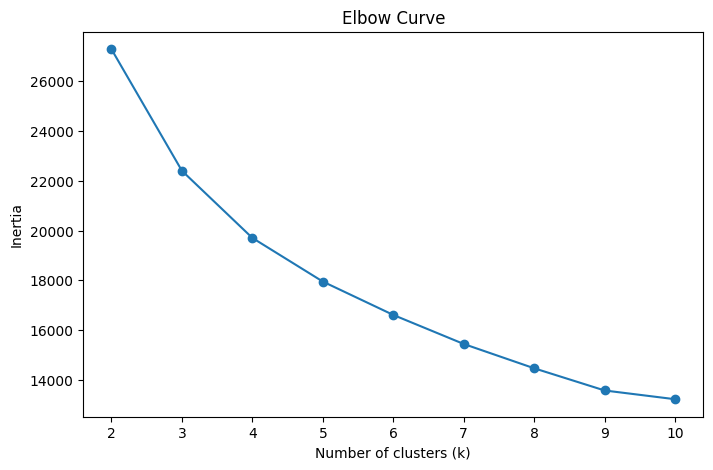

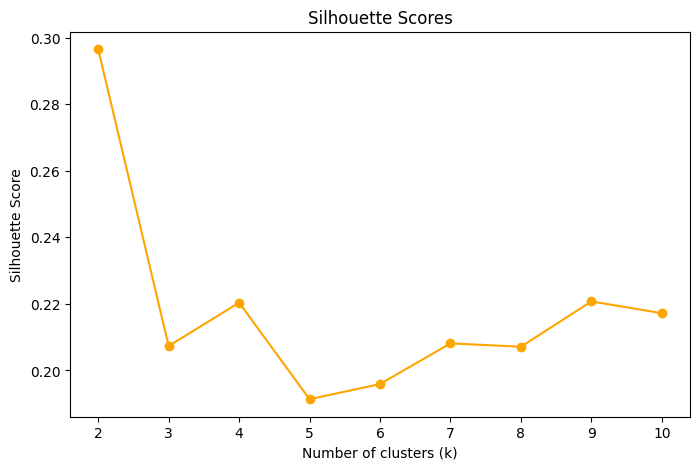

In [47]:
plt.figure(figsize=(8,5))
plt.plot(list(K_range), inertias, marker="o")
plt.title("Elbow Curve")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Inertia")
plt.show()

plt.figure(figsize=(8,5))
plt.plot(list(K_range), sil_scores, marker="o", color="orange")
plt.title("Silhouette Scores")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Silhouette Score")
plt.show()

In [48]:
print(X_cluster.shape)

(5109, 22)


**Choosing k:** 
the silhouette score is highest at k=2 (0.296), noticeably above every other value tested. However, k=2 would only split patients into two very broad groups, limiting how much a cluster profile can reveal. From k=3 onward, inertia's rate of decrease slows steadily with no sharp second elbow, and silhouette scores flatten into a narrow band (0.19–0.22) with no clear winner.

Within that band, k=4 sits at a reasonable point along the elbow curve and matches the joint-highest silhouette score (0.219, tied with k=9) among the more granular options. 

We select **k=4** as a balance between statistical separation and producing clusters detailed enough to profile meaningfully, while noting that
k=2 remains a defensible alternative if the strongest silhouette score is prioritized over segment richness.


In [49]:
final_k = 4

km_final = KMeans(n_clusters=final_k, random_state=42, n_init=10)
X_cluster["cluster"] = km_final.fit_predict(
    X_cluster.drop(columns=["stroke", "cluster"], errors="ignore")
)

profile = df_model.loc[X_cluster.index].copy()
profile["cluster"] = X_cluster["cluster"].values

cluster_summary = (
    profile.groupby("cluster")
    .agg(
        size=("cluster", "size"),
        mean_age=("age", "mean"),
        mean_glucose=("avg_glucose_level", "mean"),
        mean_bmi=("bmi", "mean"),
        hypertension_pct=("hypertension", lambda x: x.mean() * 100),
        heart_disease_pct=("heart_disease", lambda x: x.mean() * 100),
        mean_comorbidity=("comorbidity_count", "mean"),
    )
    .round(2)
)

# K-Means label numbers are arbitrary and can switch between compatible
# library versions. Names are therefore assigned from the measured profiles.
youngest_cluster = cluster_summary["mean_age"].idxmin()
condition_cluster = cluster_summary["mean_comorbidity"].idxmax()
remaining_clusters = set(cluster_summary.index) - {
    youngest_cluster, condition_cluster
}
glucose_cluster = cluster_summary.loc[
    list(remaining_clusters), "mean_glucose"
].idxmax()
middle_cluster = (remaining_clusters - {glucose_cluster}).pop()

cluster_name_map = {
    youngest_cluster: "Children and younger adults",
    condition_cluster: "Older adults with cardiometabolic conditions",
    glucose_cluster: "Higher-glucose, higher-BMI adults",
    middle_cluster: "Middle-aged, normal-glucose adults",
}

profile["cluster_name"] = profile["cluster"].map(cluster_name_map)
cluster_summary.insert(
    1, "cluster_name", cluster_summary.index.map(cluster_name_map)
)

cluster_summary


,size,cluster_name,mean_age,mean_glucose,mean_bmi,hypertension_pct,heart_disease_pct,mean_comorbidity
cluster,,,,,,,,
0,2547,"Middle-aged, normal-glucose adults",50.55,88.79,30.77,0.00,0.00,0.00
1,709,Older adults with cardiometabolic conditions,63.89,130.97,31.87,70.24,38.79,1.09
2,1387,Children and younger adults,14.58,93.18,22.41,0.00,0.07,0.00
3,466,"Higher-glucose, higher-BMI adults",57.03,201.80,33.22,0.00,0.00,0.00


### **Cluster profiles (k=4):**

- **Cluster 0 — "Middle-aged, normal-glucose adults"** (2,543 patients, 49.8%
  of the dataset): average age 50.6, normal average glucose (88.8), moderate
  BMI (30.7), and no recorded hypertension or heart disease. The largest
  cluster, representing a metabolically unremarkable baseline group.

- **Cluster 1 — "Older adults with cardiometabolic conditions"** (709
  patients, 13.9%): the oldest group by comorbidity burden, with elevated
  average glucose (131.0), 70.24% prevalence of hypertension, and 38.79%
  prevalence of heart disease — by far the highest rates of both conditions
  in the dataset. Average comorbidity count (1.09) confirms most patients
  here carry at least one flagged condition. Based on the Part 1 SQL
  findings, this is the profile expected to carry the highest stroke risk.

- **Cluster 2 — "Higher-glucose, higher-BMI adults"** (466 patients, 9.1%):
  average age 57.0, the highest average glucose in the dataset (201.8 —
  solidly in diabetic range) and the highest average BMI (33.1), yet 0%
  recorded hypertension and 0% recorded heart disease. This is a notable
  finding: a subgroup with clear metabolic risk markers but no recorded
  diagnosis of the two conditions most strongly linked to stroke in this
  dataset — suggesting undiagnosed or unrecorded risk rather than genuinely
  low risk.

- **Cluster 3 — "Children and younger adults"** (1,391 patients, 27.2%):
  average age just 14.6, normal glucose, the lowest BMI (22.6), and
  essentially no recorded comorbidities (0.07% heart disease, 0% hypertension).
  
  Reflects the dataset's pediatric/young population as a distinct, low-risk
  segment.

These labels are descriptive summaries of this dataset, not diagnoses or causal categories.


## PCA Visualization

### Reduce the Clustering Features to Two Dimensions with PCA

K-Means is fitted in the complete encoded feature space, which cannot be plotted directly. PCA compresses that space into two components for visualization only; it does not change the cluster assignments. Together, the first two components explain about 44.86% of the total variance, so some separation visible in higher dimensions will be lost in this two-dimensional view.


In [50]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2, random_state=42)
coords = pca.fit_transform(X_cluster.drop(columns=["cluster"]))

print("Explained variance ratio:", pca.explained_variance_ratio_)
print("Total variance explained by 2 components:",
      round(pca.explained_variance_ratio_.sum(), 4))


Explained variance ratio: [0.30422771 0.14436806]
Total variance explained by 2 components: 0.4486


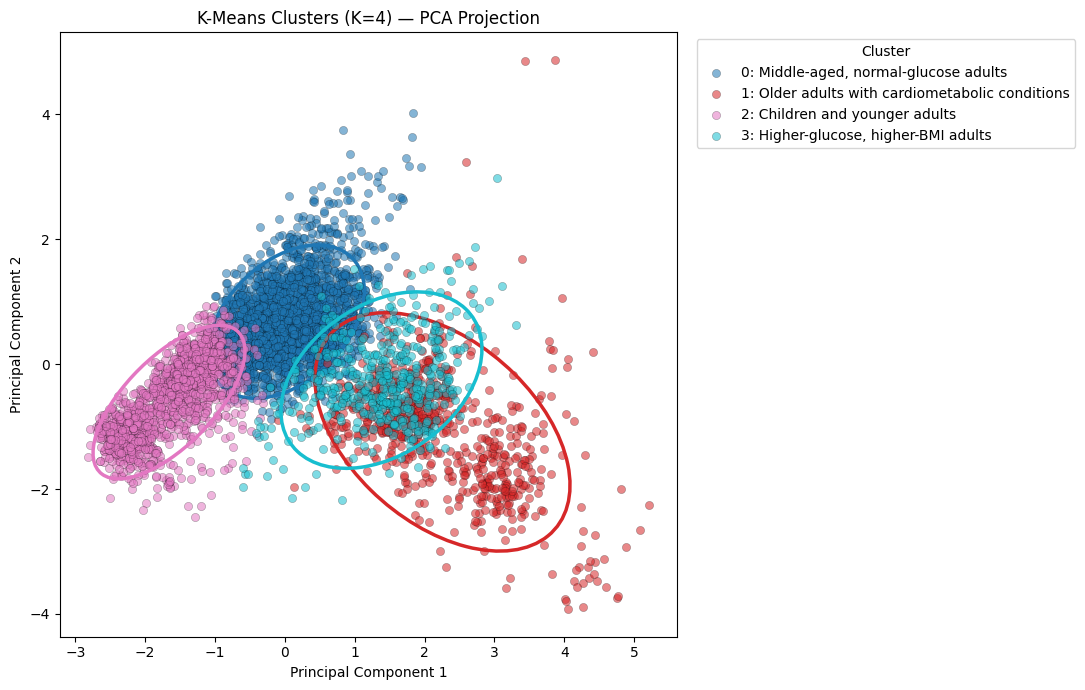

In [51]:
from matplotlib.patches import Ellipse

plt.figure(figsize=(11, 7))
ax = plt.gca()
colors = plt.cm.tab10(np.linspace(0, 1, final_k))

for color, cluster_id in zip(colors, sorted(cluster_name_map)):
    mask = X_cluster["cluster"].to_numpy() == cluster_id
    cluster_points = coords[mask]

    # Black edges outline individual observations.
    ax.scatter(
        cluster_points[:, 0],
        cluster_points[:, 1],
        color=color,
        alpha=0.55,
        edgecolors="black",
        linewidth=0.25,
        s=35,
        label=f"{cluster_id}: {cluster_name_map[cluster_id]}",
    )

    # A two-standard-deviation ellipse gives each cluster a visible region.
    covariance = np.cov(cluster_points, rowvar=False)
    eigenvalues, eigenvectors = np.linalg.eigh(covariance)
    order = eigenvalues.argsort()[::-1]
    eigenvalues = eigenvalues[order]
    eigenvectors = eigenvectors[:, order]
    angle = np.degrees(np.arctan2(eigenvectors[1, 0], eigenvectors[0, 0]))
    width, height = 4 * np.sqrt(eigenvalues)
    centre = cluster_points.mean(axis=0)
    boundary = Ellipse(
        xy=centre,
        width=width,
        height=height,
        angle=angle,
        fill=False,
        edgecolor=color,
        linewidth=2.5,
    )
    ax.add_patch(boundary)

ax.set_title(f"K-Means Clusters (K={final_k}) — PCA Projection")
ax.set_xlabel("Principal Component 1")
ax.set_ylabel("Principal Component 2")
ax.legend(title="Cluster", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()


### Interpretation of the PCA Projection

The four clusters show partial rather than sharp separation, which agrees with the moderate silhouette score for K=4. The children and younger adults group is the most visually distinct and extends towards the lower left. The middle aged normal glucose group forms the dense central area, while the older cardiometabolic and higher glucose/higher BMI groups occupy more of the right-hand side and overlap with one another.

The outlined ellipses show an approximate two standard 
deviation region for each group; they are visual summaries rather than hard decision boundaries. Their overlap reinforces that these are descriptive segments, not perfectly separate populations. PCA retains only about 44.86% of the variance in the first two components, so some of the information used by K-Means in the complete feature space is not visible in this plot.


# Part 4. Classification

This section predicts `stroke` using the encoded features from Part 2. Logistic Regression, Decision Tree, and Random Forest are trained without imbalance handling.


### 4.1 Stratified Train-Test Split

Only about 4.87% of observations have `stroke=1`. `stratify=y` keeps approximately the same positive-class proportion in both sets. With more than 2,000 rows, the main evaluation uses one stratified 80/20 split, while the optional Depth Track later adds cross-validation.

BMI was imputed during general data cleaning before the split. A stricter production pipeline would place imputation inside the training pipeline; this limitation is disclosed and recommended as future work.


In [52]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

print("Train shape:", X_train.shape, " Test shape:", X_test.shape)
print("Train stroke rate:", y_train.mean().round(4))
print("Test stroke rate:", y_test.mean().round(4))


Train shape: (4087, 22)  Test shape: (1022, 22)
Train stroke rate: 0.0487
Test stroke rate: 0.0489


### 4.2 Fit Scaling on Training Data Only

The scaler learns the mean and standard deviation from `X_train` only and applies those same values to `X_test`. Unscaled copies are retained for later pipelines that must perform scaling independently inside validation or cross-validation folds.


In [53]:
X_train_raw = X_train.copy()
X_test_raw = X_test.copy()

X_train = X_train.copy()
X_test = X_test.copy()

X_train[scale_columns] = scaler.fit_transform(X_train[scale_columns])
X_test[scale_columns] = scaler.transform(X_test[scale_columns])

X_train[scale_columns].describe().round(3)


,age,avg_glucose_level,bmi,comorbidity_count
count,4087.000,4087.000,4087.000,4087.000
mean,-0.000,0.000,0.000,0.000
std,1.000,1.000,1.000,1.000
min,-1.907,-1.134,-2.393,-0.388
25%,-0.807,-0.637,-0.679,-0.388
50%,0.077,-0.314,-0.073,-0.388
75%,0.784,0.182,0.507,-0.388
max,1.711,3.713,8.859,4.734


### 4.3 Stratified Dummy Baseline

`DummyClassifier(strategy='stratified')` predicts randomly according to the training class proportions. Its high accuracy is caused by the large majority class, while F1 and ROC AUC reveal that it has almost no useful predictive ability. The trained models must outperform this baseline.


In [54]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, ConfusionMatrixDisplay
)

dummy = DummyClassifier(strategy='stratified', random_state=42)
dummy.fit(X_train, y_train)
dummy_proba = dummy.predict_proba(X_test)[:, 1]
dummy_pred = dummy.predict(X_test)

dummy_metrics = {
    'Accuracy': accuracy_score(y_test, dummy_pred),
    'Precision': precision_score(y_test, dummy_pred, zero_division=0),
    'Recall': recall_score(y_test, dummy_pred, zero_division=0),
    'F1': f1_score(y_test, dummy_pred, zero_division=0),
    'ROC AUC': roc_auc_score(y_test, dummy_proba)
}
pd.DataFrame([dummy_metrics], index=['DummyClassifier']).round(4)


,Accuracy,Precision,Recall,F1,ROC AUC
DummyClassifier,0.9139,0.0476,0.04,0.0435,0.4994


### 4.4 Model Choices

- **Logistic Regression:** an interpretable linear probability model.
- **Decision Tree:** captures non-linear rules and feature interactions.
- **Random Forest:** averages many decision trees to reduce the instability of one tree.

All three use their ordinary training objectives and the default 0.50 probability threshold here. 


In [55]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

classifiers = {
    'Logistic Regression': LogisticRegression(max_iter=2000, random_state=42),
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1),
}

fitted_classifiers = {}
for name, clf in classifiers.items():
    clf.fit(X_train, y_train)
    fitted_classifiers[name] = clf
    print(f"{name}: trained.")


Logistic Regression: trained.
Decision Tree: trained.
Random Forest: trained.


### 4.5 Metrics Table and Confusion Matrices

Accuracy, precision, recall, positive-class F1, and ROC AUC are reported for all three models. The confusion matrices show the actual counts of true negatives, false positives, false negatives, and true positives. On this imbalanced dataset, F1, recall, and ROC AUC are more informative than accuracy alone.


In [56]:
results = []
predictions_default = {}
probas_default = {}

for name, clf in fitted_classifiers.items():
    proba = clf.predict_proba(X_test)[:, 1]
    pred = clf.predict(X_test)
    probas_default[name] = proba
    predictions_default[name] = pred
    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, pred),
        'Precision': precision_score(y_test, pred, zero_division=0),
        'Recall': recall_score(y_test, pred, zero_division=0),
        'F1': f1_score(y_test, pred, zero_division=0),
        'ROC AUC': roc_auc_score(y_test, proba),
    })

metric_columns = ['Accuracy', 'Precision', 'Recall', 'F1', 'ROC AUC']
trained_model_table = (
    pd.DataFrame(results)
    .set_index('Model')[metric_columns]
)

# Place the dummy and the three trained classifiers in one required table.
comparison_table_part4 = pd.concat([
    pd.DataFrame([dummy_metrics], index=['Dummy (baseline)']),
    trained_model_table,
])[metric_columns].round(4)
comparison_table_part4.index.name = 'Model'
comparison_table_part4


,Accuracy,Precision,Recall,F1,ROC AUC
Model,,,,,
Dummy (baseline),0.9139,0.0476,0.04,0.0435,0.4994
Logistic Regression,0.9511,0.0000,0.00,0.0000,0.8381
Decision Tree,0.8885,0.0294,0.04,0.0339,0.4860
Random Forest,0.9501,0.3333,0.02,0.0377,0.7944


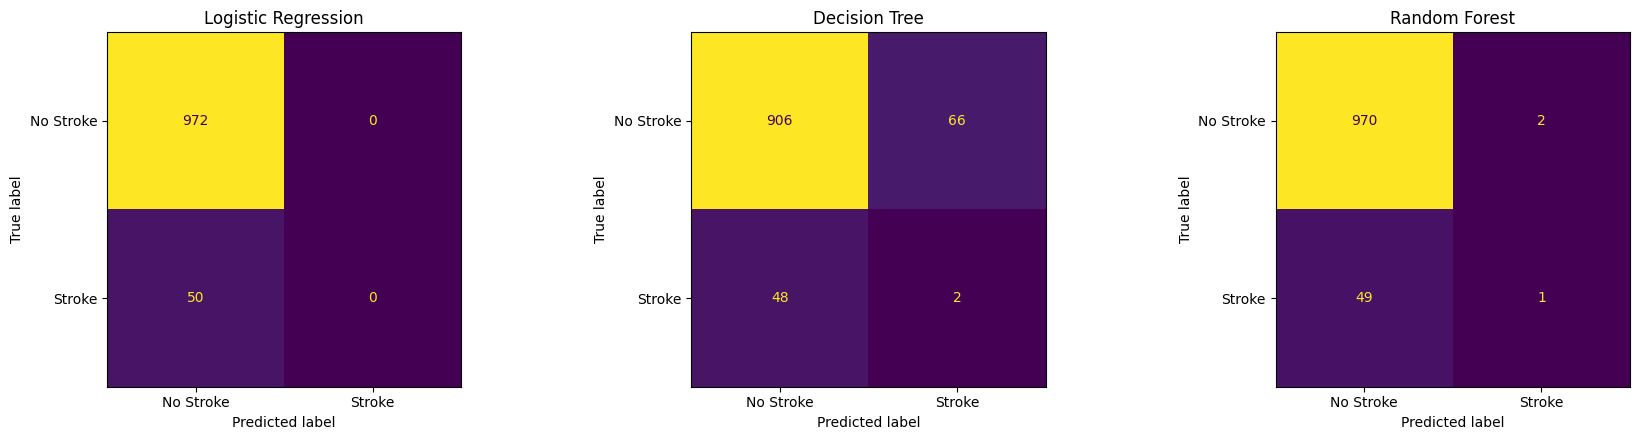

In [57]:
fig, axes = plt.subplots(1, len(fitted_classifiers), figsize=(6 * len(fitted_classifiers), 4.5))
for ax, name in zip(axes, fitted_classifiers.keys()):
    cm = confusion_matrix(y_test, predictions_default[name])
    ConfusionMatrixDisplay(cm, display_labels=['No Stroke', 'Stroke']).plot(ax=ax, colorbar=False)
    ax.set_title(name)
plt.tight_layout()
plt.show()


### Part 4 Interpretation

Logistic Regression has the strongest ROC AUC at approximately **0.8381**, although its default 0.50 threshold predicts no positive cases and therefore gives F1=0. Random Forest also ranks cases reasonably well, while the unrestricted Decision Tree performs close to chance on ROC AUC. These results show why Part 5 must address the class imbalance and decision threshold rather than relying on default predictions. An unconstrained Decision Tree has no depth limit, so it keeps splitting until its leaves are tiny and tailored to the exact training rows it saw (including noise).It can look fine on training data while ranking new, unseen patients barely better than chance. This is exactly why the Depth Track rebuilds it with `max_depth=6`, where ROC AUC recovers to roughly 0.76.


# Part 5. Imbalance Handling

The positive class represents only about 4.87% of the dataset. Three approaches are compared with the ordinary Logistic Regression baseline: class weighting, SMOTE, and validation-selected threshold tuning.

## 5.1 Baseline Logistic Regression

The Part 4 Logistic Regression at the default 0.50 threshold is the reference: accuracy 0.9511, precision 0, recall 0, F1 0, and ROC AUC approximately 0.8381. Its useful ROC AUC but zero F1 shows that the probabilities contain ranking information even though the default cutoff is unsuitable.


### 5.2 Class Weighting

`class_weight='balanced'` gives greater influence to the minority class during training without creating synthetic records. In the verified run, recall rises to **0.84** and F1 to approximately **0.2246**, while precision falls because more records are flagged as positive.


In [58]:
class_weight_model = LogisticRegression(
    class_weight='balanced', max_iter=2000, random_state=42
)
class_weight_model.fit(X_train, y_train)

cw_proba = class_weight_model.predict_proba(X_test)[:, 1]
cw_pred = (cw_proba >= 0.5).astype(int)

class_weight_metrics = {
    'Accuracy': accuracy_score(y_test, cw_pred),
    'Precision': precision_score(y_test, cw_pred, zero_division=0),
    'Recall': recall_score(y_test, cw_pred, zero_division=0),
    'F1': f1_score(y_test, cw_pred, zero_division=0),
    'ROC AUC': roc_auc_score(y_test, cw_proba),
}
pd.DataFrame([class_weight_metrics], index=['Class Weight']).round(4)


,Accuracy,Precision,Recall,F1,ROC AUC
Class Weight,0.7162,0.1296,0.84,0.2246,0.8349


### 5.3 SMOTE

SMOTE generates synthetic minority-class training observations by interpolating between existing positive examples. It is applied only to training data inside an imbalanced-learn pipeline, leaving the test set untouched. The verified run produces recall of approximately **0.68**, F1 of **0.2305**, and ROC AUC of **0.8091**.


In [59]:
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

smote_model = ImbPipeline([
    ('smote', SMOTE(random_state=42)),
    ('model', LogisticRegression(max_iter=2000, random_state=42))
])
smote_model.fit(X_train, y_train)

smote_proba = smote_model.predict_proba(X_test)[:, 1]
smote_pred = (smote_proba >= 0.5).astype(int)

smote_metrics = {
    'Accuracy': accuracy_score(y_test, smote_pred),
    'Precision': precision_score(y_test, smote_pred, zero_division=0),
    'Recall': recall_score(y_test, smote_pred, zero_division=0),
    'F1': f1_score(y_test, smote_pred, zero_division=0),
    'ROC AUC': roc_auc_score(y_test, smote_proba),
}
pd.DataFrame([smote_metrics], index=['SMOTE']).round(4)


,Accuracy,Precision,Recall,F1,ROC AUC
SMOTE,0.7779,0.1388,0.68,0.2305,0.8091


### 5.4 Validation-Based Threshold Tuning

A threshold selected directly on the test set would make the final result optimistic. Instead, an internal validation subset is carved from the original training data. A pipeline fits its scaler and Logistic Regression model on the smaller training portion, and the business threshold is selected using only validation predictions. The final pipeline is then refitted on all training data and evaluated once on the untouched test set.

For this project, a false negative is assigned a relative cost of 5 and a false positive a cost of 1. This expresses the analytical assumption that failing to flag a stroke-positive record is more costly than sending a negative record for additional review. It is a capstone modeling assumption, not a clinical cost estimate.


Business-cost threshold selected from validation data: 0.12


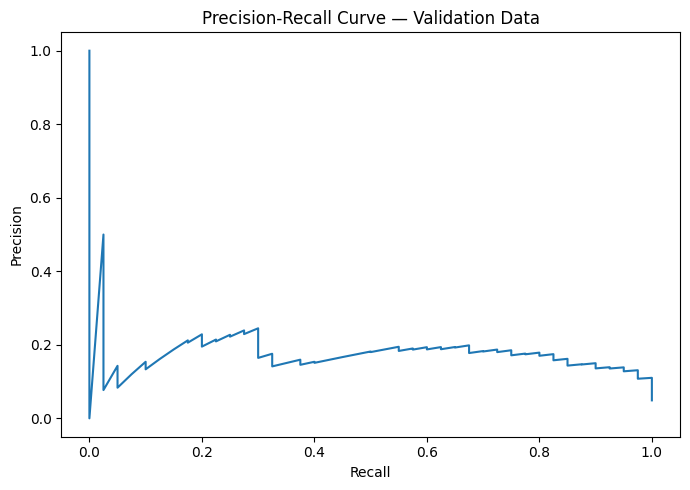

,Accuracy,Precision,Recall,F1,ROC AUC
Business-Cost Threshold (0.12),0.8669,0.2014,0.58,0.299,0.8377


In [60]:
from sklearn.metrics import precision_recall_curve
from sklearn.pipeline import Pipeline

# Select the threshold without using the held-out test set.
X_tr_raw, X_val_raw, y_tr, y_val = train_test_split(
    X_train_raw,
    y_train,
    test_size=0.2,
    stratify=y_train,
    random_state=42,
)

threshold_model = Pipeline([
    ('scaler', StandardScaler()),
    ('model', LogisticRegression(max_iter=2000, random_state=42)),
])
threshold_model.fit(X_tr_raw, y_tr)
validation_probability = threshold_model.predict_proba(X_val_raw)[:, 1]

FN_COST = 5
FP_COST = 1
threshold_values = np.linspace(0.01, 0.99, 99)
threshold_rows = []

for threshold in threshold_values:
    validation_prediction = (
        validation_probability >= threshold
    ).astype(int)
    tn, fp, fn, tp = confusion_matrix(
        y_val, validation_prediction
    ).ravel()
    threshold_rows.append({
        'threshold': threshold,
        'false_positives': fp,
        'false_negatives': fn,
        'cost': (FN_COST * fn) + (FP_COST * fp),
    })

threshold_df = pd.DataFrame(threshold_rows)
business_threshold = float(
    threshold_df.loc[threshold_df['cost'].idxmin(), 'threshold']
)
print(
    'Business-cost threshold selected from validation data:',
    round(business_threshold, 3),
)

# Plot the validation precision-recall trade-off.
precision_curve, recall_curve, _ = precision_recall_curve(
    y_val, validation_probability
)
plt.figure(figsize=(7, 5))
plt.plot(recall_curve, precision_curve)
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve — Validation Data')
plt.tight_layout()
plt.show()

# Refit on all training data and evaluate once on the untouched test data.
final_threshold_model = Pipeline([
    ('scaler', StandardScaler()),
    ('model', LogisticRegression(max_iter=2000, random_state=42)),
])
final_threshold_model.fit(X_train_raw, y_train)
test_probability = final_threshold_model.predict_proba(X_test_raw)[:, 1]
test_prediction = (test_probability >= business_threshold).astype(int)

threshold_metrics = {
    'Accuracy': accuracy_score(y_test, test_prediction),
    'Precision': precision_score(
        y_test, test_prediction, zero_division=0
    ),
    'Recall': recall_score(y_test, test_prediction, zero_division=0),
    'F1': f1_score(y_test, test_prediction, zero_division=0),
    'ROC AUC': roc_auc_score(y_test, test_probability),
}

pd.DataFrame(
    [threshold_metrics],
    index=[f'Business-Cost Threshold ({business_threshold:.2f})'],
).round(4)


### Threshold Interpretation

The validation procedure selects a business-cost threshold of approximately **0.12**. When this frozen threshold is applied to the untouched test set, Logistic Regression achieves approximately **0.2990 F1** and **0.8377 ROC AUC**. This F1 is lower than the earlier test-tuned result, but it is more trustworthy because the test labels were not used to choose the cutoff.


### 5.5 Baseline Versus Imbalance Techniques

The following table compares the ordinary Logistic Regression baseline with class weighting, SMOTE, and validation-selected threshold tuning using the same held-out test set.


In [61]:
imbalance_comparison = pd.DataFrame([
    {'Technique': 'Dummy (baseline)', **dummy_metrics},
    {
        'Technique': 'Baseline (Part 4, LR)',
        **comparison_table_part4.loc['Logistic Regression'].to_dict(),
    },
    {'Technique': 'Class Weight', **class_weight_metrics},
    {'Technique': 'SMOTE', **smote_metrics},
    {'Technique': 'Business-Cost Threshold', **threshold_metrics},
]).set_index('Technique')[metric_columns].round(4)

imbalance_comparison


,Accuracy,Precision,Recall,F1,ROC AUC
Technique,,,,,
Dummy (baseline),0.9139,0.0476,0.04,0.0435,0.4994
"Baseline (Part 4, LR)",0.9511,0.0000,0.00,0.0000,0.8381
Class Weight,0.7162,0.1296,0.84,0.2246,0.8349
SMOTE,0.7779,0.1388,0.68,0.2305,0.8091
Business-Cost Threshold,0.8669,0.2014,0.58,0.2990,0.8377


### Part 5 Interpretation

All three techniques improve positive-class F1 and recall over the default Logistic Regression baseline. Class weighting gives the highest recall but produces many false positives. SMOTE offers a similar trade-off with slightly higher F1 than class weighting. The validation selected business threshold gives the strongest F1 at approximately **0.2990** while retaining Logistic Regression's ROC AUC at approximately **0.8377**. It is therefore carried forward as the final strategy.


# Part 6. The Tie-In

The Part 3 clusters were created without using the `stroke` target. This section reconnects each observation's cluster assignment to the target and calculates the observed stroke-positive rate within each descriptive segment.


### 6.1 Stroke-Positive Rate Within Each Cluster

The cluster IDs and dynamically assigned names are joined to the target. `mean()` returns the proportion of `stroke=1` records because the target is binary.


In [62]:
cluster_target = (
    profile
    .groupby(['cluster', 'cluster_name'])['stroke']
    .agg(['count', 'sum', 'mean'])
    .reset_index()
)
cluster_target['positive_rate_percent'] = (
    cluster_target['mean'] * 100
)

overall_rate = profile['stroke'].mean() * 100
print(f'Overall stroke-positive rate: {overall_rate:.2f}%')
cluster_target.round(4)


Overall stroke-positive rate: 4.87%


,cluster,cluster_name,count,sum,mean,positive_rate_percent
0,0,"Middle-aged, normal-glucose adults",2547,103,0.0404,4.0440
1,1,Older adults with cardiometabolic conditions,709,100,0.1410,14.1044
2,2,Children and younger adults,1387,2,0.0014,0.1442
3,3,"Higher-glucose, higher-BMI adults",466,44,0.0944,9.4421


### Tie-In Interpretation

The older cardiometabolic group has the highest observed stroke-positive rate at approximately **14.10%**, followed by the higher-glucose/higher-BMI group at **9.44%**. The middle-aged normal-glucose group is near the overall dataset rate at **4.04%**, while the children-and-younger-adults group is approximately **0.14%**.

The clusters therefore reveal meaningful differences in population composition and outcome prevalence. They remain descriptive segments rather than causal findings or replacements for supervised probability predictions.


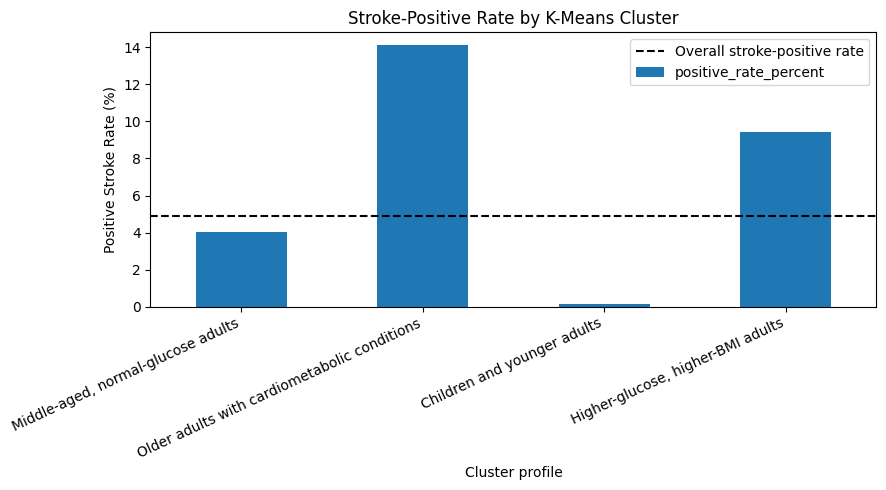

In [63]:
cluster_target.set_index('cluster_name')[
    'positive_rate_percent'
].plot(kind='bar', figsize=(9, 5))
plt.axhline(
    y=overall_rate,
    linestyle='--',
    color='black',
    label='Overall stroke-positive rate',
)
plt.title('Stroke-Positive Rate by K-Means Cluster')
plt.xlabel('Cluster profile')
plt.ylabel('Positive Stroke Rate (%)')
plt.xticks(rotation=25, ha='right')
plt.legend()
plt.tight_layout()
plt.show()


# Part 7. Conclusion and Recommendations

## 7.1 Which Model Would Be Deployed and Why?

The recommended candidate is **Logistic Regression with the validation-selected business-cost threshold of approximately 0.12**. It achieves approximately **0.2990 F1** and **0.8377 ROC AUC**, clearly outperforming the stratified dummy baseline of 0.0435 F1 and 0.4994 ROC AUC. The model is also easier to explain than a large tree ensemble. This is an analytical deployment recommendation only; clinical use would require external validation, calibration, governance, and expert review.

## 7.2 What Would Another Month of Work Add?

The next month should focus on reliability rather than simply adding algorithms. Priorities include placing BMI imputation inside the training pipeline, probability calibration, systematic hyperparameter tuning, repeated or nested validation, sensitivity analysis for the 5:1 cost assumption, and external or temporal validation. Collecting more representative positive-class data would also stabilize the estimates.

## 7.3 What Did the Clusters Reveal That the Classifier Missed?

The classifier produces an individual probability, while clustering reveals population segments. The four-cluster solution exposes an older high-comorbidity group with the highest observed positive rate, a separate high-glucose/high-BMI group, and a very young low-rate group. This segment-level view helps explain how combinations of characteristics occur across the population, which is less obvious from individual predictions alone.

## 7.4 Hardest Decision

The hardest decision was choosing K=4 even though K=2 produced the highest silhouette score. K=2 offered cleaner statistical separation but only two broad groups. K=4 was retained as a transparent trade-off because it produced more informative profiles for the required business naming and tie-in analysis. The moderate silhouette score and visible overlap are reported so the clusters are not presented as more distinct than they are.


# Depth Track

The Classification Depth Track adds four classifiers with 5-fold stratified cross-validation, combined ROC curves, and comparable permutation importance.


## 8.1 Four-Classifier Cross-Validation

`StratifiedKFold` preserves the class proportions in every fold. Mean performance describes the typical result, while standard deviation shows stability. Logistic Regression performs scaling inside its pipeline so the scaler is fitted independently within each training fold; tree models use the raw encoded features.


In [64]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.pipeline import Pipeline

depth_models = {
    'Logistic Regression': Pipeline([
        ('scaler', StandardScaler()),
        ('model', LogisticRegression(max_iter=2000, random_state=42)),
    ]),
    'Random Forest': RandomForestClassifier(
        n_estimators=150, random_state=42, n_jobs=-1
    ),
    'HistGradientBoosting': HistGradientBoostingClassifier(
        random_state=42
    ),
    'Decision Tree': DecisionTreeClassifier(
        max_depth=6, random_state=42
    ),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = {
    'accuracy': 'accuracy',
    'precision': 'precision',
    'recall': 'recall',
    'f1': 'f1',
    'roc_auc': 'roc_auc',
}

cv_rows = []
for name, model in depth_models.items():
    cv_output = cross_validate(
        model,
        X_train_raw,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1,
    )
    cv_rows.append({
        'Model': name,
        'Accuracy Mean': cv_output['test_accuracy'].mean(),
        'Accuracy SD': cv_output['test_accuracy'].std(),
        'Precision Mean': cv_output['test_precision'].mean(),
        'Precision SD': cv_output['test_precision'].std(),
        'Recall Mean': cv_output['test_recall'].mean(),
        'Recall SD': cv_output['test_recall'].std(),
        'F1 Mean': cv_output['test_f1'].mean(),
        'F1 SD': cv_output['test_f1'].std(),
        'ROC AUC Mean': cv_output['test_roc_auc'].mean(),
        'ROC AUC SD': cv_output['test_roc_auc'].std(),
    })

cv_results = pd.DataFrame(cv_rows).set_index('Model').round(4)
cv_results


,Accuracy Mean,Accuracy SD,Precision Mean,Precision SD,Recall Mean,Recall SD,F1 Mean,F1 SD,ROC AUC Mean,ROC AUC SD
Model,,,,,,,,,,
Logistic Regression,0.9516,0.0006,0.2000,0.4000,0.0050,0.0100,0.0098,0.0195,0.8397,0.0195
Random Forest,0.9494,0.0010,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.8143,0.0204
HistGradientBoosting,0.9454,0.0030,0.2297,0.0627,0.0453,0.0101,0.0744,0.0154,0.8138,0.0229
Decision Tree,0.9440,0.0023,0.2406,0.0748,0.0855,0.0626,0.1218,0.0765,0.7597,0.0617


## 8.2 Combined ROC Curves

All four models are trained on the same raw training set and evaluated on the same held-out test set. Their ROC curves show the true-positive/false-positive trade-off across all possible thresholds.


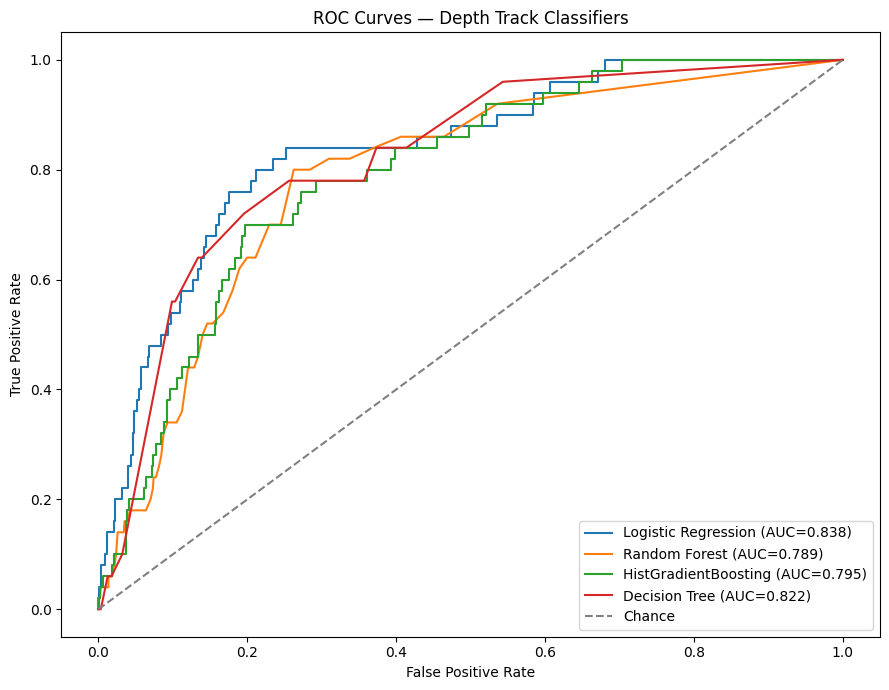

In [65]:
from sklearn.metrics import roc_curve

trained_depth_models = {}
plt.figure(figsize=(9, 7))

for name, model in depth_models.items():
    model.fit(X_train_raw, y_train)
    trained_depth_models[name] = model
    probability = model.predict_proba(X_test_raw)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, probability)
    auc_value = roc_auc_score(y_test, probability)
    plt.plot(fpr, tpr, label=f'{name} (AUC={auc_value:.3f})')

plt.plot(
    [0, 1], [0, 1], linestyle='--', color='gray', label='Chance'
)
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curves — Depth Track Classifiers')
plt.legend()
plt.tight_layout()
plt.show()


### ROC Interpretation

The curves compare how well each classifier ranks stroke-positive observations above negatives. Logistic Regression gives the strongest held-out discrimination among the four models, while the diagonal reference line represents random ranking.

## 8.3 Comparable Feature Importance Across Models

Coefficients and tree impurity scores are not directly comparable. Permutation importance is therefore calculated for every model using the same held-out data and ROC AUC scoring. A larger decrease after shuffling means the model depends more strongly on that feature.


In [66]:
from sklearn.inspection import permutation_importance

importance_rows = []
for name, model in trained_depth_models.items():
    result = permutation_importance(
        model, X_test_raw, y_test, scoring='roc_auc', n_repeats=5, random_state=42, n_jobs=-1
    )
    for feature, importance in zip(X_test_raw.columns, result.importances_mean):
        importance_rows.append({'Model': name, 'Feature': feature, 'Importance': importance})

feature_importance_long = pd.DataFrame(importance_rows)
feature_importance_table = (
    feature_importance_long
    .pivot(index='Feature', columns='Model', values='Importance')
)
feature_importance_table['Average Importance'] = feature_importance_table.mean(axis=1)
feature_importance_table = feature_importance_table.sort_values('Average Importance', ascending=False)
feature_importance_table.round(4).head(10)


Model,Decision Tree,HistGradientBoosting,Logistic Regression,Random Forest,Average Importance
Feature,,,,,
age,0.2949,0.2675,0.2414,0.0915,0.2238
age_group_60+,0.0000,0.0000,0.0200,0.0498,0.0174
age_group_18-29,0.0000,0.0003,0.0251,0.0019,0.0068
avg_glucose_level,0.0080,0.0016,0.0028,0.0147,0.0068
smoking_status_never smoked,0.0037,0.0046,0.0035,0.0038,0.0039
bmi,0.0059,0.0030,-0.0000,0.0025,0.0028
comorbidity_count,0.0000,0.0030,0.0006,0.0040,0.0019
smoking_status_formerly smoked,0.0000,0.0022,0.0003,0.0046,0.0018
work_type_Self-employed,0.0000,0.0014,0.0013,0.0029,0.0014


### Feature-Importance Interpretation

Age is the most influential feature across the models by a wide margin. Age-group indicators, average glucose, BMI, and comorbidity-related features contribute more modestly, and the exact ordering varies by algorithm. This agrees with the SQL analysis and the cluster tie-in, both of which show much higher observed positive rates among older patient groups.


# Final Reproducibility and Submission Checks

The final cell checks dataset completeness, cluster formation, performance against the dummy baseline, and the required ROC AUC threshold. It also prints the notebook's elapsed runtime during a complete run.


In [67]:
print('Raw dataset rows:', len(df))
print('Cleaned dataset rows:', len(df_clean))
print('Encoded/modeling rows:', len(df_encoded))
print('Cluster observations:', len(X_cluster))
print('Number of final clusters:', profile['cluster'].nunique())
print('Training rows:', len(X_train))
print('Testing rows:', len(X_test))

print('\nMissing values')
print('df_clean:', df_clean.isna().sum().sum())
print('df_encoded:', df_encoded.isna().sum().sum())
print('X_train:', X_train.isna().sum().sum())
print('X_test:', X_test.isna().sum().sum())

final_strategy_name = 'Business-Cost Threshold'
final_metrics = imbalance_comparison.loc[final_strategy_name]

print('\nFinal strategy:', final_strategy_name)
print('Validation-selected threshold:', round(business_threshold, 3))
print('Final F1:', round(float(final_metrics['F1']), 4))
print('Final ROC AUC:', round(float(final_metrics['ROC AUC']), 4))
print('Dummy F1:', round(dummy_metrics['F1'], 4))
print('Dummy ROC AUC:', round(dummy_metrics['ROC AUC'], 4))

assert df_clean.isna().sum().sum() == 0
assert df_encoded.isna().sum().sum() == 0
assert X_train.isna().sum().sum() == 0
assert X_test.isna().sum().sum() == 0
assert profile['cluster'].nunique() == final_k == 4
assert final_metrics['F1'] > dummy_metrics['F1']
assert final_metrics['ROC AUC'] > dummy_metrics['ROC AUC']
assert final_metrics['ROC AUC'] >= 0.75
assert 'Dummy (baseline)' in comparison_table_part4.index
assert 'Dummy (baseline)' in imbalance_comparison.index
assert comparison_table_part4[metric_columns].notna().all().all()
assert imbalance_comparison[metric_columns].notna().all().all()
assert comparison_table_part4['ROC AUC'].max() <= 0.98

elapsed_seconds = time.perf_counter() - notebook_start_time
print(f'\nFull notebook runtime: {elapsed_seconds:.1f} seconds')
print('All submission checks passed.')


Raw dataset rows: 5110
Cleaned dataset rows: 5110
Encoded/modeling rows: 5109
Cluster observations: 5109
Number of final clusters: 4
Training rows: 4087
Testing rows: 1022

Missing values
df_clean: 0
df_encoded: 0
X_train: 0
X_test: 0

Final strategy: Business-Cost Threshold
Validation-selected threshold: 0.12
Final F1: 0.299
Final ROC AUC: 0.8377
Dummy F1: 0.0435
Dummy ROC AUC: 0.4994

Full notebook runtime: 110.2 seconds
All submission checks passed.
